*Previous notebook: the synthetic dataset, train/val/test split, normalisation and the baseline network trained with full-batch gradient descent. — This notebook: mini-batch gradient descent and its comparison with batch and stochastic GD.*

### Setup

This notebook builds on **2.1**. The cell below re-runs `2.1_dataset_and_baseline.ipynb` silently to recreate the dataset, the normalised train/val/test splits and the network helpers (`init_params`, `forward`, `backward`, `update_params`, `mse`, `plot_loss`).

In [1]:
%%capture
%run "2.1_dataset_and_baseline.ipynb"

# MiniBatch Gradient Descent

We just learned how gradient descent works. In gradient descent, to perform a single
parameter update we iterate through all the data points in our training set. Updating the parameters of the model only after iterating through all the data points in the training set makes the gradient descent very slow and it will increase the training time
especially when we have a large dataset. 


So, we use minibatch gradient descent, in minibatch gradient descent, we update the parameters after iterating some batch of data points. Let us say the batch size is 50
which means that we update the parameter of the model after iterating through 50 data
points instead of updating the parameter after iterating through each individual data point.

Guidelines for choosing mini-batch size:
- If small training set (< 2000 examples) - use batch gradient descent.
- It has to be a power of 2 (because of the way computer memory is layed out and accessed, sometimes your code runs faster if your mini-batch size is a power of 2): 64, 128, 256, 512, 1024, ... Make sure that mini-batch fits in CPU/GPU memory.

Mini-batch size is a hyperparameter.

In [2]:
def minibatch_gd(X_tr, y_tr, X_v, y_v, layer_sizes, lr=1e-2, epochs=2000, batch_size=32, seed=0):
    params = init_params(layer_sizes, seed=seed)
    train_loss, val_loss = [], []
    m = X_tr.shape[0]

    start = time.time()
    
    for _ in range(epochs):
        idx = np.random.permutation(m)
        X_shuffled = X_tr[idx]
        y_shuffled = y_tr[idx]

        for s in range(0, m, batch_size):
            X_batch = X_shuffled[s : s + batch_size]
            y_batch = y_shuffled[s : s + batch_size]
            y_hat, cache = forward(X_batch, params)
            grads        = backward(y_batch, y_hat, params, cache)
            params       = update_params(params, grads, lr)

        y_hat_tr, _ = forward(X_tr, params)
        y_hat_v,  _ = forward(X_v,  params)
        train_loss.append(mse(y_tr, y_hat_tr))
        val_loss.append(mse(y_v,  y_hat_v))

    end = time.time()
    elapsed = end - start

    return params, train_loss, val_loss, elapsed

Final train MSE: 0.0411  |  val MSE: 0.0426  |  time: 6.95s


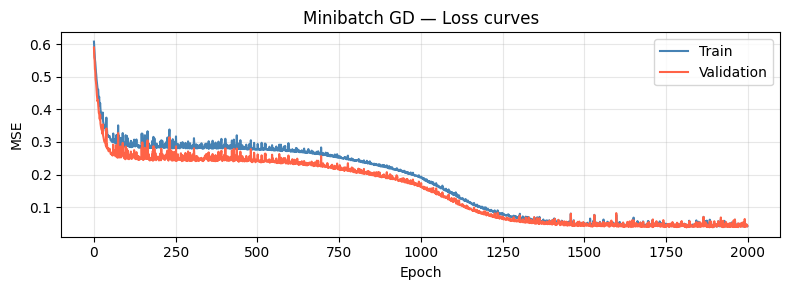

In [3]:
params_mb, tl_mb, vl_mb, t_mb = minibatch_gd(
    X_train_n, y_train, X_val_n, y_val,
    layer_sizes=[1, 32, 32, 1]
)

print(f'Final train MSE: {tl_mb[-1]:.4f}  |  val MSE: {vl_mb[-1]:.4f}  |  time: {t_mb:.2f}s')

plot_loss(tl_mb, vl_mb, title='Minibatch GD — Loss curves')

### Comparison with other techniques

Given "m" the number of sample in the training set, we have:

- (mini batch size = m) ==> Batch gradient descent
- (mini batch size = 1) ==> Stochastic gradient descent (SGD)
- (mini batch size = between 1 and m) ==> Mini-batch gradient descent

In mini-batch algorithm, the cost won't go down with each step as it does in batch algorithm. It could contain some ups and downs but generally it has to go down (unlike the batch gradient descent where cost function descreases on each iteration). 

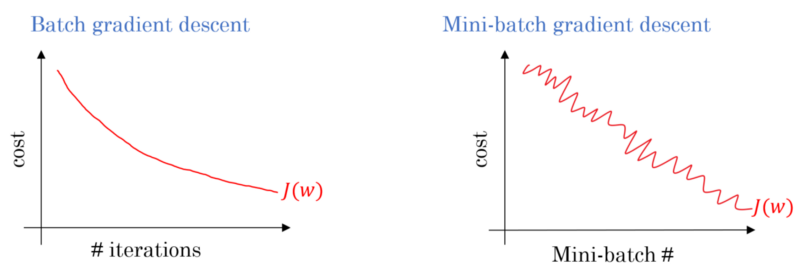

- Batch gradient descent: too long per iteration (epoch)
- Stochastic gradient descent:
    - too noisy regarding cost minimization (can be reduced by using smaller learning rate)
    - won't ever converge (reach the minimum cost)
    - lose speedup from vectorization
- Mini-batch gradient descent:
    - faster learning (you have the vectorization advantage)
    - make progress without waiting to process the entire training set
    - doesn't always exactly converge (oscelates in a very small region, but you can reduce learning rate)